In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
sup = pd.read_csv('aaus6_class_suppliers - aaus6_class_suppliers.csv')
con = pd.read_csv('aaus6_class_contracts - aaus6_class_contracts.csv')
po = pd.read_csv('aaus6_class_purchase_orders - aaus6_class_purchase_orders.csv')
rec = pd.read_csv('aaus6_class_goods_receipts - aaus6_class_goods_receipts.csv')
print([len(sup), len(con), len(po), len(rec)])

[60, 96, 288, 354]


In [17]:
print("suppliers: ", sup.columns)
print("contracts: ", con.columns)
print("purchase orders: ", po.columns)
print("goods receipts: ", rec.columns)
print('Unique supplier keys:', sup.supplier_key.nunique())
print('Unique contract keys:', con.contract_key.nunique())
print('Unique purchase order keys:', po.order_key.nunique())
print('Unique goods receipt keys:', rec.receipt_key.nunique())


suppliers:  Index(['supplier_key', 'supplier_name', 'supplier_region', 'certification',
       'service_focus', 'rating'],
      dtype='object')
contracts:  Index(['contract_key', 'supplier_key', 'procurement_method',
       'contract_category', 'contract_amount_etb', 'approval_stage',
       'start_date'],
      dtype='object')
purchase orders:  Index(['order_key', 'contract_key', 'purchase_unit', 'item_category',
       'order_date', 'order_amount_etb', 'priority', 'approval_status'],
      dtype='object')
goods receipts:  Index(['receipt_key', 'order_key', 'received_date', 'quantity_accepted',
       'inspection_result', 'receiving_office'],
      dtype='object')
Unique supplier keys: 60
Unique contract keys: 96
Unique purchase order keys: 288
Unique goods receipt keys: 354


In [24]:
print('Purchase order unique contract kyes:', po.contract_key.nunique())

Purchase order unique contract kyes: 102


In [25]:
# Execute inner join on contract_key
joined_inner = po.merge(
  con,
on='contract_key',
how='inner'
)
print('Orders:', len(po))
print('Inner result:', len(joined_inner))
print('Lost orders:', 
len(po)-len(joined_inner))

Orders: 288
Inner result: 279
Lost orders: 9


In [31]:
# Execute left join on contract_key
joined_left = po.merge(
  con,
on='contract_key',
how='left'
)
print('Orders:', len(po))
print('Inner result:', len(joined_left))
print('Lost orders:', 
len(po)-len(joined_left))

joined_left.shape

Orders: 288
Inner result: 288
Lost orders: 0


(288, 14)

In [32]:
# Execute right join on contract_key
joined_right = po.merge(
  con,
on='contract_key',
how='right'
)
print('Orders:', len(po))
print('Inner result:', len(joined_right))
print('Lost orders:', 
len(po)-len(joined_right))

joined_right.shape

Orders: 288
Inner result: 282
Lost orders: 6


(282, 14)

In [34]:
right_view = po.merge(
con, on='contract_key',
how='right'
)
print('Right rows:', len(right_view))
print('Contract IDs:',
right_view.contract_key.nunique())
print('Orders missing:',
right_view.order_key.isna().sum())
right_view.shape

Right rows: 282
Contract IDs: 96
Orders missing: 3


(282, 14)

In [38]:
outer = po.merge(
con, on='contract_key',
how='outer', indicator=True
)
print(outer['_merge']
.value_counts().to_dict())
print('Rows:', len(outer))

outer

{'both': 279, 'left_only': 9, 'right_only': 3}
Rows: 291


,order_key,contract_key,purchase_unit,item_category,order_date,order_amount_etb,priority,approval_status,supplier_key,procurement_method,contract_category,contract_amount_etb,approval_stage,start_date,_merge
0,PO-00035,C-0001,Lideta,Solar Controller,2026-07-26,61635.0,Urgent,Released,S-007,RFQ,Water Kiosk,139317.0,Active,2026-01-02,both
1,PO-00131,C-0001,Lideta,Solar Controller,2026-09-04,42691.0,Urgent,Released,S-007,RFQ,Water Kiosk,139317.0,Active,2026-01-02,both
2,PO-00227,C-0001,Lideta,Solar Controller,2026-03-08,118747.0,Urgent,Released,S-007,RFQ,Water Kiosk,139317.0,Active,2026-01-02,both
3,PO-00070,C-0002,Gullele,Solar Controller,2026-06-11,98270.0,High,Pending,S-014,Framework,SCADA Gateway,158634.0,Under Review,2026-01-03,both
4,PO-00166,C-0002,Gullele,Solar Controller,2026-07-21,79326.0,High,Pending,S-014,Framework,SCADA Gateway,158634.0,Under Review,2026-01-03,both
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
286,PO-00160,C-X160,Gullele,SCADA Gateway,2026-06-21,56760.0,High,Pending,NaN,NaN,NaN,NaN,NaN,NaN,left_only
287,PO-00192,C-X192,Merkato,Water Kiosk,2026-04-22,82112.0,Routine,Approved,NaN,NaN,NaN,NaN,NaN,NaN,left_only
288,PO-00224,C-X224,Akaki,Lab Analyzer,2026-02-21,107464.0,Urgent,Released,NaN,NaN,NaN,NaN,NaN,NaN,left_only
289,PO-00256,C-X256,Gullele,SCADA Gateway,2026-07-31,37816.0,High,Pending,NaN,NaN,NaN,NaN,NaN,NaN,left_only


In [39]:
audit = po.merge(
con, on='contract_key',
how='left', indicator=True,
validate='many_to_one'
)
print(audit['_merge']
.value_counts().to_dict())
print('Unmatched keys:', audit.loc[
audit['_merge']=='left_only',
'contract_key'].nunique())

{'both': 279, 'left_only': 9, 'right_only': 0}
Unmatched keys: 9


In [40]:
miss = audit.loc[audit['_merge']=='left_only']
print('Rows needing review:', len(miss))
print('Units:', miss.purchase_unit.value_counts().
head(3).to_dict())

Rows needing review: 9
Units: {'Akaki': 3, 'Gullele': 3, 'Merkato': 3}


In [42]:
semi = po.loc[po.contract_key.isin(
con.contract_key)].copy()
print('Matched orders:', len(semi))
print('Unmatched removed:', 
len(po)-len(semi))

Matched orders: 279
Unmatched removed: 9


In [43]:
anti = po.loc[~po.contract_key.isin(
con.contract_key)].copy()
print('Review rows:', len(anti))
print('Reconciles:', 
len(semi)+len(anti)==len(po))

Review rows: 9
Reconciles: True


In [45]:
anti = po.loc[~po.contract_key.isin(
con.contract_key)].copy()
print('Review rows:', len(anti))
print('Reconciles:', 
len(semi)+len(anti)==len(po))

Review rows: 9
Reconciles: True


In [46]:
legacy = sup.rename(columns={
'supplier_key':'vendor_reference'})
map_view = con.merge(legacy,
left_on='supplier_key',
right_on='vendor_reference',
how='left', indicator=True)
print(map_view['_merge'].value_counts().to_dict())

{'both': 92, 'left_only': 4, 'right_only': 0}


In [49]:
left_temp = po.rename(columns={'priority':'status'})
right_temp = con.rename(columns={'approval_stage':'status'})
sfx = left_temp.merge(right_temp, 
on='contract_key',
how='left', suffixes=('_order','_contract'))
print([x for x in sfx if x.startswith('status')])
po

['status_order', 'status_contract']


,order_key,contract_key,purchase_unit,item_category,order_date,order_amount_etb,priority,approval_status
0,PO-00001,C-0011,Bole,Water Kiosk,2026-02-06,28761,High,Pending
1,PO-00002,C-0022,Akaki,Water Kiosk,2026-02-11,32522,Urgent,Released
2,PO-00003,C-0033,Kirkos,SCADA Gateway,2026-02-16,36283,Routine,Approved
3,PO-00004,C-0044,Gullele,SCADA Gateway,2026-02-21,40044,High,Pending
4,PO-00005,C-0055,Lideta,SCADA Gateway,2026-02-26,43805,Urgent,Released
...,...,...,...,...,...,...,...,...
283,PO-00284,C-0052,Akaki,Lab Analyzer,2026-05-12,48124,Urgent,Released
284,PO-00285,C-0063,Kirkos,Solar Controller,2026-05-17,51885,Routine,Approved
285,PO-00286,C-0074,Gullele,Solar Controller,2026-05-22,55646,High,Pending
286,PO-00287,C-0085,Lideta,Solar Controller,2026-05-27,59407,Urgent,Released


In [52]:
enriched = (po.merge(con, on='contract_key',
how='left', validate='many_to_one')
.merge(sup, on='supplier_key', how='left',
validate='many_to_one'))
print('Rows:', len(enriched))
print('Known regions:', 
enriched.supplier_region.notna().sum())
enriched.shape

Rows: 288
Known regions: 270


(288, 19)

In [53]:
kiosk = (enriched.loc[
    enriched.item_category == 'Water Kiosk'
].copy())
print('Kiosk-related orders:', len(kiosk))
print('Known suppliers:',
    kiosk.supplier_name.notna().sum())

Kiosk-related orders: 72
Known suppliers: 60


In [55]:
stage1 = po.merge(con, on='contract_key',how='left')
stage2 = stage1.merge(sup, on='supplier_key',how='left', indicator=True)
print(stage2['_merge'].value_counts().to_dict())

{'both': 270, 'left_only': 18, 'right_only': 0}


In [56]:
po_rec = po.merge(rec, on='order_key',
    how='left', validate='one_to_many')
print('Purchase orders:', len(po))
print('Rows after join:', len(po_rec))
print('Orders without receipt:',
      po_rec.receipt_key.isna().sum())

Purchase orders: 288
Rows after join: 336
Orders without receipt: 0


In [57]:
gr_summary = rec.groupby('order_key', 
as_index=False).agg(
accepted_qty=('quantity_accepted', 'sum'),
receipt_count=('receipt_key', 'count'))
order_summary = po.merge(gr_summary, on='order_key',
how='left', validate='one_to_one')
print(len(order_summary), 
order_summary.receipt_count.notna().sum())

288 288


In [63]:
checked = po.merge(con, on='contract_key',how='left', validate='many_to_one')
print('Validated rows:', len(checked))

Validated rows: 288


In [64]:
try:
    po.merge(rec, on='order_key',
    validate='one_to_one')
except pd.errors.MergeError:
    print('Blocked: order_key repeats in receipts')

Blocked: order_key repeats in receipts


In [65]:
counts = rec.order_key.value_counts()
print('Keys with >1 receipt:', (counts>1).sum())
print('Maximum receipts per order:', counts.max())

Keys with >1 receipt: 48
Maximum receipts per order: 2


In [68]:
contract_idx = con.set_index('supplier_key')
supplier_idx = sup.set_index('supplier_key')
joined_idx = contract_idx.join(supplier_idx,
how='left', rsuffix='_master')
print('Indexed join rows:', len(joined_idx))
joined_idx

Indexed join rows: 96


,contract_key,procurement_method,contract_category,contract_amount_etb,approval_stage,start_date,supplier_name,supplier_region,certification,service_focus,rating
supplier_key,,,,,,,,,,,
S-007,C-0001,RFQ,Water Kiosk,139317,Active,2026-01-02,Synthetic Partner 007,Oromia,Conditional,Lab Analyzer,3.64
S-014,C-0002,Framework,SCADA Gateway,158634,Under Review,2026-01-03,Synthetic Partner 014,Amhara,Under Review,SCADA Gateway,4.48
S-021,C-0003,Open Tender,Lab Analyzer,177951,Approved,2026-01-04,Synthetic Partner 021,Addis Ababa,Certified,Water Kiosk,3.16
S-028,C-0004,RFQ,Solar Controller,197268,Active,2026-01-05,Synthetic Partner 028,Oromia,Conditional,Solar Controller,4.00
S-035,C-0005,Framework,Water Kiosk,216585,Under Review,2026-01-06,Synthetic Partner 035,Amhara,Under Review,Lab Analyzer,4.84
...,...,...,...,...,...,...,...,...,...,...,...
S-044,C-0092,Framework,Solar Controller,197164,Under Review,2026-04-03,Synthetic Partner 044,Amhara,Under Review,Solar Controller,3.76
S-051,C-0093,Open Tender,Water Kiosk,216481,Approved,2026-04-04,Synthetic Partner 051,Addis Ababa,Certified,Lab Analyzer,4.60
S-058,C-0094,RFQ,SCADA Gateway,235798,Active,2026-04-05,Synthetic Partner 058,Oromia,Conditional,SCADA Gateway,3.28


In [69]:
by_index = contract_idx.merge(supplier_idx,
left_index=True, right_index=True,
how='left')
print('Equal row counts:',
len(by_index) == len(joined_idx))

Equal row counts: True


In [ ]:
eycols = ['inspection_quarter', 'inspection_key']
base = all_ins.drop(columns='site_area')\
        .set_index(keycols)
lookup = all_ins[keycols+['site_area']]\
          .set_index(keycols)
mi_join = base.join(lookup, how='left',
                    validate='one_to_one')

NameError: name 'all_ins' is not defined

In [74]:
# Load staff directory
staff = pd.read_csv('aaus6_class_staff_directory - aaus6_class_staff_directory.csv')
# Perform self-join to map manager details
org = staff.merge(
staff[['employee_key', 'employee_label']],
left_on='manager_key', right_on='employee_key',
how='left', suffixes=('', '_manager')
)
print('Staff:', len(org))
print('No assigned manager:', 
org.employee_label_manager.isna().sum())

Staff: 84
No assigned manager: 6


In [79]:
q1 = pd.read_csv('aaus6_class_inspections_Q1 - aaus6_class_inspections_Q1.csv')
q2 = pd.read_csv('aaus6_class_inspections_Q2 - aaus6_class_inspections_Q2.csv')
combined = pd.concat([q1, q2], ignore_index=True)
print('Quarter sizes:', len(q1), len(q2))
print('Combined:', len(combined))
print('q1-only:',q1.head(2))
print(q2.head(2))

Quarter sizes: 64 64
Combined: 128
q1-only:   inspection_key site_area inspection_type  elapsed_days  finding_count  \
0   IK-2026-0001      Bole           Civil             2              1   
1   IK-2026-0002     Akaki          Safety             3              2   

  inspection_quarter inspector_group  
0                 Q1          Team-2  
1                 Q1          Team-3  
  inspection_key site_area inspection_type  elapsed_days  finding_count  \
0   IK-2026-0065    Lideta           Civil            12              0   
1   IK-2026-0066   Merkato          Safety            13              1   

  inspection_quarter followup_required  
0                 Q2                No  
1                 Q2               Yes  


In [77]:
print('Q1-only:', set(q1.columns) - set(q2.columns))
print('Q2-only:', set(q2.columns) - set(q1.columns))
print('Missing inspector_group:',
combined.inspector_group.isna().sum())

Q1-only: {'inspector_group'}
Q2-only: {'followup_required'}
Missing inspector_group: 64


In [83]:
keyed = pd.concat([q1, q2], keys=['Q1', 'Q2'])
print('Index levels:', keyed.index.nlevels)
print('Q1 rows:', len(keyed.loc['Q1']))
print('Q2 rows:', len(keyed.loc['Q2']))
keyed

Index levels: 2
Q1 rows: 64
Q2 rows: 64


inspection_key site_area inspection_type  elapsed_days  finding_count  \
Q1 0    IK-2026-0001      Bole           Civil             2              1   
   1    IK-2026-0002     Akaki          Safety             3              2   
   2    IK-2026-0003    Kirkos   Commissioning             4              3   
   3    IK-2026-0004   Gullele      Electrical             5              4   
   4    IK-2026-0005    Lideta           Civil             6              0   
...              ...       ...             ...           ...            ...   
Q2 59   IK-2026-0124   Gullele      Electrical            17              4   
   60   IK-2026-0125    Lideta           Civil            18              0   
   61   IK-2026-0126   Merkato          Safety             1              1   
   62   IK-2026-0127      Bole   Commissioning             2              2   
   63   IK-2026-0128     Akaki      Electrical             3              3   

      inspection_quarter inspector_group followup_required  
Q1 0                  Q1          Team-2               NaN  
   1                  Q1          Team-3               NaN  
   2                  Q1          Team-4               NaN  
   3                  Q1          Team-1               NaN  
   4                  Q1          Team-2               NaN  
...                  ...             ...               ...  
Q2 59                 Q2             NaN                No  
   60                 Q2             NaN                No  
   61                 Q2             NaN               Yes  
   62                 Q2             NaN                No  
   63                 Q2             NaN                No  

[128 rows x 8 columns]

In [82]:
a = sup[['supplier_key']].head(3).set_index('supplier_key')
b = sup[['rating']].head(3)
b.index = a.index
wide = pd.concat([a,b], axis=1)
print('Columns:', wide.columns.tolist())
print('Rows:', len(wide))

Columns: ['rating']
Rows: 3


In [84]:
# Execute automated reconciliation assertions
assert len(semi) + len(anti) == len(po)
assert len(joined_left) == len(po)
assert len(combined) == len(q1) + len(q2)
print('Core integrity checks: PASSED')

Core integrity checks: PASSED


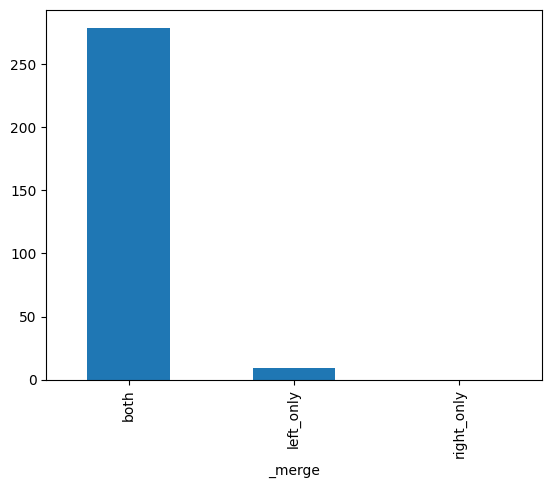

In [85]:
c = audit['_merge']
c.value_counts().plot.bar()
plt.show()

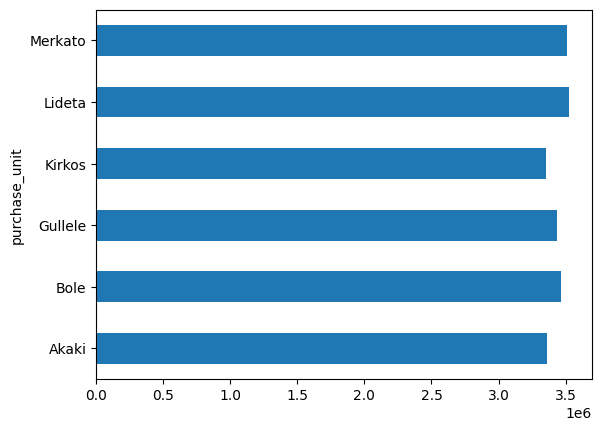

In [86]:
g = enriched.groupby(
'purchase_unit')
v = g.order_amount_etb.sum()
v.plot.barh()
plt.show()

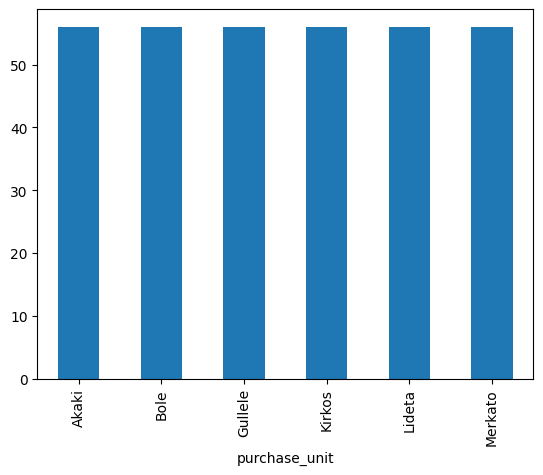

In [87]:
g = po_rec.groupby(
'purchase_unit')
v = g.receipt_key.count()
v.plot.bar()
plt.show()

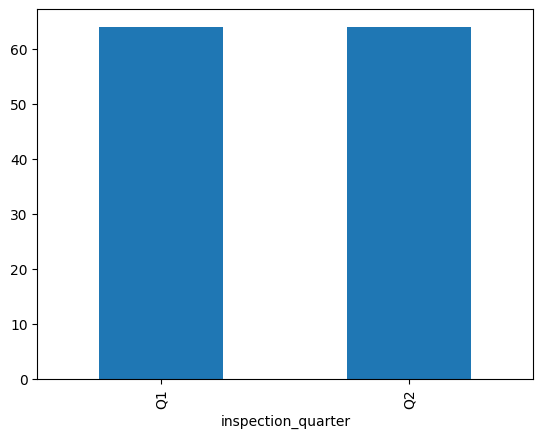

In [88]:
c = combined[
'inspection_quarter']
c.value_counts().plot.bar()
plt.show()

In [91]:
inv_pay = inv.merge(pay,on='invoice_key',how='left',validate='one_to_many',indicator=True)
print('Invoices:',len(inv))
print('Joined rows:',len(inv_pay))
print(inv_pay['_merge'].value_counts().to_dict())

NameError: name 'inv' is not defined

In [92]:
payments_by_invoice = pay.groupby(
'invoice_key', as_index=False).agg(
    total_paid=('paid_etb', 'sum'))
settlement = inv.merge(payments_by_invoice,
  on='invoice_key', how='left',
  validate='one_to_one')
print('Invoice-level rows:', len(settlement))
print('Invoices with payment:',
  settlement.total_paid.notna().sum())

NameError: name 'pay' is not defined